In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


here we use pyarrow because mene jab pandas me load krne kaa try kia toh wo pura data bhut bade hone ke karam RAM me load ni ho paa rha thaa toh unhone khud hi pyarrow dia hai toh me whi use kra 

In [15]:
import pyarrow.parquet as pq

path = r"D:\Projects\Wonder fund\wnn_connectome_starterpack\wnn_connectome_starterpack\datasets\train.parquet"

pf = pq.ParquetFile(path)

print("Rows:", pf.metadata.num_rows)
print("Columns:", pf.metadata.num_columns)
print("Row groups:", pf.num_row_groups)

print("\nSchema:")
print(pf.schema)

Rows: 212140000
Columns: 117
Row groups: 10607

Schema:
required group field_id=-1 schema {
  optional int32 field_id=-1 seq_ix;
  optional int32 field_id=-1 step_in_seq;
  optional boolean field_id=-1 need_prediction;
  optional float field_id=-1 i0_p0;
  optional float field_id=-1 i0_p1;
  optional float field_id=-1 i0_p2;
  optional float field_id=-1 i0_p3;
  optional float field_id=-1 i0_p4;
  optional float field_id=-1 i0_p5;
  optional float field_id=-1 i0_p6;
  optional float field_id=-1 i0_p7;
  optional float field_id=-1 i0_p8;
  optional float field_id=-1 i0_p9;
  optional float field_id=-1 i0_p10;
  optional float field_id=-1 i0_p11;
  optional float field_id=-1 i0_p12;
  optional float field_id=-1 i0_p13;
  optional float field_id=-1 i0_p14;
  optional float field_id=-1 i0_p15;
  optional float field_id=-1 i0_p16;
  optional float field_id=-1 i0_p17;
  optional float field_id=-1 i0_p18;
  optional float field_id=-1 i0_p19;
  optional float field_id=-1 i0_p20;
  optional flo

# data Analysis
1. approx 212 million rows mili
2. 117 columns
3. so total about 24.8 billion values. hai 


In [18]:

# 1. First row group
group = pf.read_row_group(0)

sample = group.slice(0, 10).to_pandas()

print("Shape:", sample.shape)

print("\nColumns:")
print(sample.columns.tolist())

print("\nFirst 10 rows:")
print(sample.to_string())


Shape: (10, 117)

Columns:
['seq_ix', 'step_in_seq', 'need_prediction', 'i0_p0', 'i0_p1', 'i0_p2', 'i0_p3', 'i0_p4', 'i0_p5', 'i0_p6', 'i0_p7', 'i0_p8', 'i0_p9', 'i0_p10', 'i0_p11', 'i0_p12', 'i0_p13', 'i0_p14', 'i0_p15', 'i0_p16', 'i0_p17', 'i0_p18', 'i0_p19', 'i0_p20', 'i0_p21', 'i0_v0', 'i0_v1', 'i0_v2', 'i0_v3', 'i0_v4', 'i0_v5', 'i0_v6', 'i0_v7', 'i0_v8', 'i0_v9', 'i0_v10', 'i0_v11', 'i0_v12', 'i0_v13', 'i0_v14', 'i0_v15', 'i0_v16', 'i0_v17', 'i0_v18', 'i0_v19', 'i0_v20', 'i0_v21', 'i0_dp0', 'i0_dp1', 'i0_dp2', 'i0_dp3', 'i0_dv0', 'i0_dv1', 'i0_dv2', 'i0_dv3', 'i1_p0', 'i1_p1', 'i1_p2', 'i1_p3', 'i1_p4', 'i1_p5', 'i1_p6', 'i1_p7', 'i1_p8', 'i1_p9', 'i1_p10', 'i1_p11', 'i1_p12', 'i1_p13', 'i1_p14', 'i1_p15', 'i1_p16', 'i1_p17', 'i1_p18', 'i1_p19', 'i1_p20', 'i1_p21', 'i1_v0', 'i1_v1', 'i1_v2', 'i1_v3', 'i1_v4', 'i1_v5', 'i1_v6', 'i1_v7', 'i1_v8', 'i1_v9', 'i1_v10', 'i1_v11', 'i1_v12', 'i1_v13', 'i1_v14', 'i1_v15', 'i1_v16', 'i1_v17', 'i1_v18', 'i1_v19', 'i1_v20', 'i1_v21', 'i1_dp0'


1. Pehle 99 steps har seq_ix (sequence index) me need_prediction = False diya gaya hai, like wo hum **GRU ko warm-up/context dene ke liye use karenge**, jisse model ko initial sequence ki information mil jayegi.

2. Har seq_ix ke andar **20,000 step_in_seq** hain (0 se 19,999 tak).

3. i0_p0 se i0_p10 tak jo 11 values hain wo **bid-side price-like features** hain, aur i0_p11 se i0_p21 tak jo hain wo **ask-side price-like features** hain.

4. Aise hi i0_v0 se i0_v10 tak jo 11 values hain wo **bid-side volume-like features** hain, aur i0_v11 se i0_v21 tak jo hain wo **ask-side volume-like features** hain.

5. i0_dp0 se i0_dp3 tak **4 trade-price-related features** hain.

6. i0_dv0 se i0_dv3 tak **4 trade-volume-related features** hain.

7. i1 me **same type ke 52 features** hain, bas ye **dusre instrument** ka data hai. i0 target instrument hai, i1 dusre instrument ka market data, jo model ko additional input/context ke liye diya gaya hai

8. a0 se a7 tak 

9. t0 and t1 **2 target columns** hain.


In [21]:
missing = sample.isna().sum()

print(missing[missing > 0])

Series([], dtype: int64)


**checking ki ye 20000 hi hai ya kisi or id me kamm toh ni hai and wo Warm-up check, Step order check**
we get ki koi gadbadi ni haii---> i am removing code from here so that jyda bada na ho jaye EDA 
1. Bad row groups: 0
    Every sequence has exactly 20,000 rows.

2. Sequences with wrong step order: 0
    All sequences have step_in_seq = 0 → 19999.

3. Sequences with invalid warm-up: 0

In [28]:
i0_p = [f"i0_p{i}" for i in range(22)]
i0_v = [f"i0_v{i}" for i in range(22)]

i0_dp = [f"i0_dp{i}" for i in range(4)]
i0_dv = [f"i0_dv{i}" for i in range(4)]

i1_p = [f"i1_p{i}" for i in range(22)]
i1_v = [f"i1_v{i}" for i in range(22)]

i1_dp = [f"i1_dp{i}" for i in range(4)]
i1_dv = [f"i1_dv{i}" for i in range(4)]

additional = [f"a{i}" for i in range(8)]

since data bhut bada hai toh hm isme sampling lekr check krege like representative sampling lege 

In [30]:
sample_parts = []

for rg in range(pf.num_row_groups):

    table = pf.read_row_group(
        rg,
        columns=input_cols
    )

    df = table.to_pandas()

    # 20 approximately equally spaced rows
    idx = np.linspace(
        0,
        len(df) - 1,
        20,
        dtype=int
    )

    sample_parts.append(df.iloc[idx])

sample_df = pd.concat(
    sample_parts,
    ignore_index=True
)

print(sample_df.shape)

(212140, 112)


In [31]:
summary = sample_df.describe().T

print(summary)

          count      mean       std       min       25%       50%       75%  \
i0_p0  212140.0 -1.591274  0.340440 -2.475077 -1.639976 -1.434200 -1.434200   
i0_p1  212140.0  0.164979  0.057137 -2.340615  0.139710  0.178175  0.191052   
i0_p2  212140.0  0.404726  0.061587 -2.345716  0.378820  0.416878  0.430727   
i0_p3  212140.0 -1.809674  0.281862 -2.485541 -1.746017 -1.746017 -1.746017   
i0_p4  212140.0 -0.120809  0.087727 -2.354492 -0.165327 -0.165327 -0.037988   
...         ...       ...       ...       ...       ...       ...       ...   
a3     212140.0 -0.184826  0.976292 -5.199337 -0.860292 -0.196055  0.480078   
a4     212140.0  0.036883  0.961750 -3.344557 -0.612066  0.040066  0.688657   
a5     212140.0 -0.457931  1.977473 -5.199337 -0.618627  0.031471  0.672615   
a6     212140.0 -0.516516  1.960725 -5.199337 -0.728698 -0.043329  0.621518   
a7     212140.0 -1.441080  2.875296 -5.199337 -5.199337  0.101452  0.799083   

            max  
i0_p0 -0.401638  
i0_p1  0.353775

In [32]:
summary[
    ["mean", "std", "min", "max"]
].sort_values("std")

,mean,std,min,max
i0_p12,0.288195,0.036940,-2.324978,1.599100
i1_p12,0.285038,0.044024,-2.410452,1.637113
i0_p17,0.062992,0.046763,-2.331804,0.704975
i1_p17,0.059536,0.052628,-2.389697,1.596044
i0_p1,0.164979,0.057137,-2.340615,0.353775
...,...,...,...,...
a3,-0.184826,0.976292,-5.199337,3.386311
a2,-0.161511,0.985077,-5.199337,2.953697
a6,-0.516516,1.960725,-5.199337,5.163194
a5,-0.457931,1.977473,-5.199337,3.983784


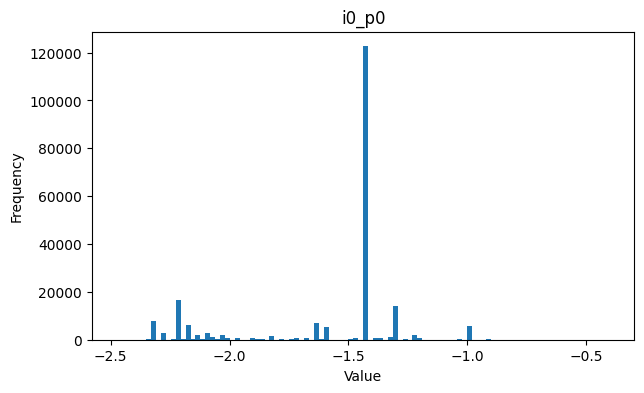

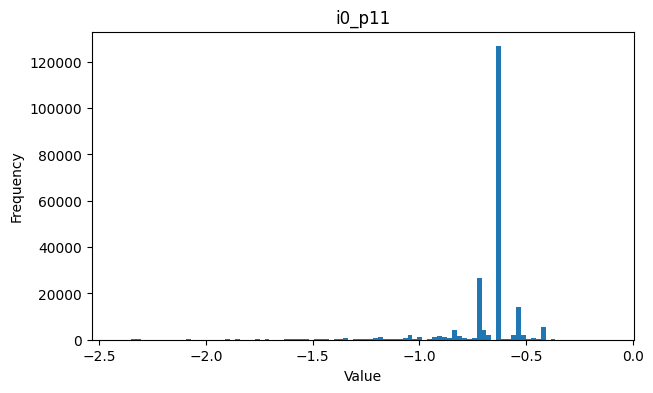

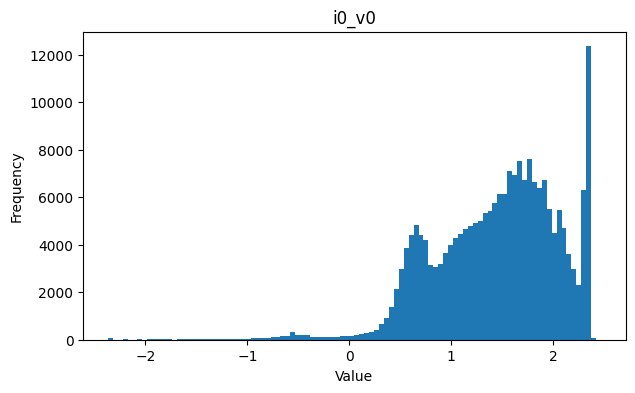

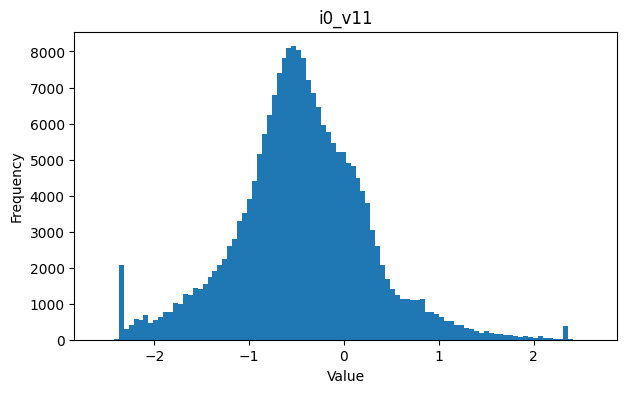

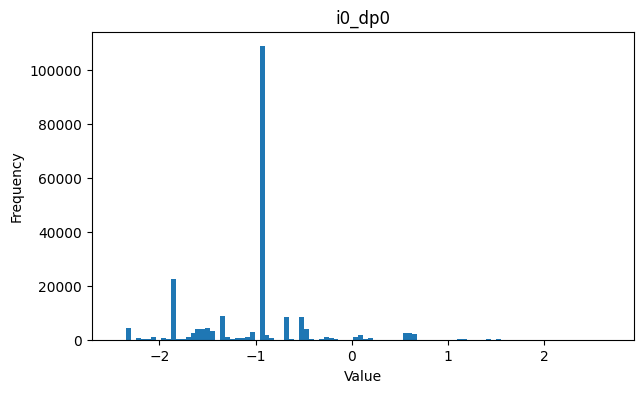

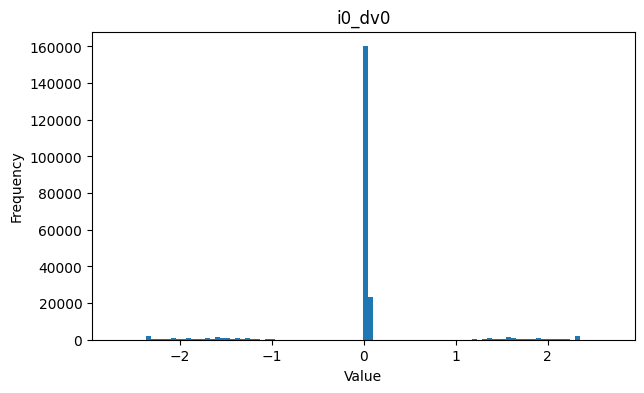

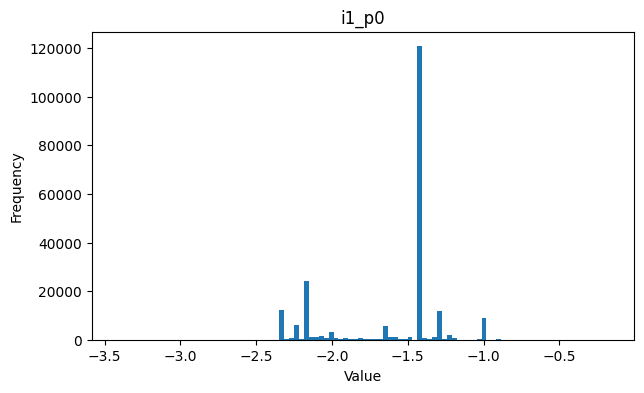

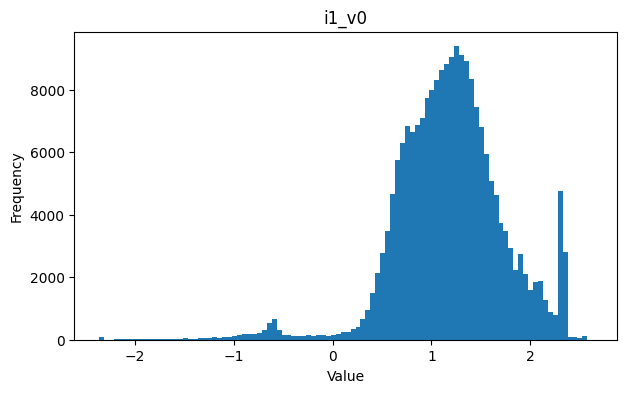

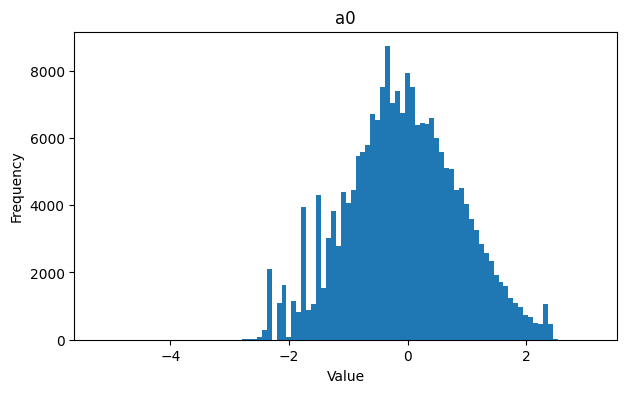

In [33]:
import matplotlib.pyplot as plt

features_to_plot = [
    "i0_p0",
    "i0_p11",
    "i0_v0",
    "i0_v11",
    "i0_dp0",
    "i0_dv0",
    "i1_p0",
    "i1_v0",
    "a0"
]

for col in features_to_plot:

    plt.figure(figsize=(7, 4))

    plt.hist(
        sample_df[col].dropna(),
        bins=100
    )

    plt.title(col)
    plt.xlabel("Value")
    plt.ylabel("Frequency")

    plt.show()